# 04 — PyCaret model comparison

Discover candidate classifiers using only the raw training split. Poisonous is the positive class (`1`). This notebook does not load the final test set, tune hyperparameters, or save a production model. This educational dataset is not evidence that real mushrooms are safe to eat.

## 2. Imports and configuration

PyCaret is not currently installed in the project environment. The code below raises an actionable install command instead of inventing results. The setup options follow the current documented `ClassificationExperiment` API.

In [21]:
from pathlib import Path
import importlib.metadata
import importlib.util
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'mushroom' / 'preprocessing.py').is_file()
     and (p / 'requirements.txt').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / 'mushroom' / 'data'
FIGURE_DIR = DATA_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'class'
TARGET_MAPPING = {'e': 0, 'p': 1}
RANDOM_STATE = 42
N_SPLITS = 5
INTERNAL_TRAIN_SIZE = 0.80

if importlib.util.find_spec('pycaret') is None:
    raise ModuleNotFoundError(
        'PyCaret is not installed in this environment. Install it with: '
        '.venv/bin/python -m pip install pycaret'
    )
from pycaret.classification import ClassificationExperiment

PYCARET_VERSION = importlib.metadata.version('pycaret')
print('PyCaret version:', PYCARET_VERSION)

ModuleNotFoundError: PyCaret is not installed in this environment. Install it with: .venv/bin/python -m pip install pycaret

## 3. Load and validate training data

Only load raw training features, encoded training labels, and the optional metadata/baseline reference. The held-out test split and already transformed data are intentionally not read.

In [ ]:
X_PATH = DATA_DIR / 'mushroom_X_train_raw.parquet'
Y_PATH = DATA_DIR / 'mushroom_y_train.parquet'
METADATA_PATH = DATA_DIR / 'mushroom_preprocessing_metadata.json'
BASELINE_PATH = DATA_DIR / 'mushroom_baseline_results.csv'
for path in (X_PATH, Y_PATH):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; run 02_data_preparation.ipynb first.')

X_train = pd.read_parquet(X_PATH)
y_frame = pd.read_parquet(Y_PATH)
if TARGET not in y_frame:
    raise ValueError(f'Missing {TARGET!r} target in {Y_PATH}.')
y_train = y_frame[TARGET].rename(TARGET)
if X_train.empty or len(X_train) != len(y_train) or not X_train.index.equals(y_train.index):
    raise ValueError('Training features and target must be non-empty and row-aligned.')
if X_train.columns.has_duplicates:
    raise ValueError('Training feature columns contain duplicates.')
if y_train.isna().any() or set(y_train.unique()) != {0, 1}:
    raise ValueError('Target must contain only 0=edible and 1=poisonous.')
for column in X_train:
    series = X_train[column]
    if pd.api.types.is_numeric_dtype(series) or isinstance(series.dtype, pd.CategoricalDtype):
        continue
    non_missing = series.dropna()
    if not non_missing.map(lambda value: isinstance(value, str)).all():
        raise TypeError(f'Unexpected training feature dtype or value type in {column!r}: {series.dtype}.')

metadata = json.loads(METADATA_PATH.read_text()) if METADATA_PATH.is_file() else None
if metadata is not None:
    if metadata.get('target_mapping') != TARGET_MAPPING:
        raise ValueError(f'Unexpected metadata target mapping: {metadata.get("target_mapping")}')
    if metadata.get('raw_feature_order') != X_train.columns.tolist():
        raise ValueError('Raw feature columns/order differ from preparation metadata.')
    numeric_features = metadata['numerical_features']
    categorical_features = metadata['categorical_features']
else:
    numeric_features = X_train.select_dtypes(include='number').columns.tolist()
    categorical_features = [c for c in X_train if c not in numeric_features]
if set(numeric_features).union(categorical_features) != set(X_train.columns):
    raise ValueError('Feature-type metadata does not match raw feature columns.')

train_data = X_train.copy()
train_data[TARGET] = y_train.astype('int8')
print(f'Training data: {len(X_train):,} rows × {X_train.shape[1]} predictors')
display(y_train.value_counts().sort_index().rename(index={0: 'Edible (0)', 1: 'Poisonous (1)'}).to_frame('count'))

Training data: 4,000 rows × 10 predictors


,count
class,
Edible (0),2486
Poisonous (1),1514


## 4–5. Configure PyCaret and metrics

PyCaret setup creates an internal train/holdout split. `train_size=1.0` is not accepted, so this exploratory experiment uses 80% of the supplied 4,000 training rows (about 3,200) for its five-fold CV and holds back about 800 rows for PyCaret's internal validation. This differs from notebook 03, which cross-validates on all 4,000 rows with the shared project preprocessor. Comparisons with that baseline are exploratory, not direct.

In [ ]:
from sklearn.metrics import balanced_accuracy_score, recall_score

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
experiment = ClassificationExperiment()
experiment.setup(
    data=train_data,
    target=TARGET,
    train_size=INTERNAL_TRAIN_SIZE,
    session_id=RANDOM_STATE,
    fold_strategy=cv,
    fold=N_SPLITS,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    imputation_type='simple',
    numeric_imputation='median',
    categorical_imputation='__missing__',
    normalize=True,
    normalize_method='zscore',
    feature_selection=False,
    remove_outliers=False,
    fix_imbalance=False,
    data_split_shuffle=True,
    data_split_stratify=True,
    n_jobs=1,
    html=False,
    verbose=True,
)

def _binary_metric_labels(values):
    labels = np.asarray(values).astype(str)
    if set(np.unique(labels)) != {'0', '1'}:
        raise ValueError(f'Expected binary labels 0/1, got {np.unique(labels).tolist()}.')
    return labels

def poisonous_recall(y_true, y_pred, sample_weight=None):
    return recall_score(
        _binary_metric_labels(y_true), _binary_metric_labels(y_pred),
        pos_label='1', sample_weight=sample_weight, zero_division=0,
    )

def balanced_accuracy(y_true, y_pred, sample_weight=None):
    return balanced_accuracy_score(
        _binary_metric_labels(y_true), _binary_metric_labels(y_pred),
        sample_weight=sample_weight,
    )

experiment.add_metric('poisonous_recall', 'Poisonous Recall', poisonous_recall,
                      target='pred', greater_is_better=True)
experiment.add_metric('balanced_accuracy_explicit', 'Balanced Accuracy', balanced_accuracy,
                      target='pred', greater_is_better=True)
print('Five stratified folds; positive class is poisonous (1).')

                    Description             Value
0                    Session id                42
1                        Target             class
2                   Target type            Binary
3           Original data shape        (4000, 11)
4        Transformed data shape        (4000, 65)
5   Transformed train set shape        (3200, 65)
6    Transformed test set shape         (800, 65)
7              Numeric features                 3
8          Categorical features                 7
9      Rows with missing values             99.8%
10                   Preprocess              True
11              Imputation type            simple
12           Numeric imputation            median
13       Categorical imputation       __missing__
14     Maximum one-hot encoding                25
15              Encoding method              None
16                    Normalize              True
17             Normalize method            zscore
18               Fold Generator   StratifiedKFold


## 6–7. Compare classifiers and review rankings

Use an explicit list of available algorithms. Optional LightGBM/XGBoost are only included if present in the model library. Bagging (Random Forest/Extra Trees) fits trees independently and aggregates them; boosting (AdaBoost/Gradient Boosting) fits learners sequentially to focus on residual errors. We inspect rankings across recall, balanced accuracy, F1, and ROC-AUC instead of relying only on accuracy.

In [ ]:
model_library = experiment.models()
available_ids = set(model_library.index.astype(str))
requested_ids = ['lr', 'dt', 'rf', 'et', 'gbc', 'ada', 'knn', 'rbfsvm', 'nb', 'lightgbm', 'xgboost']
include_models = [model_id for model_id in requested_ids if model_id in available_ids]
skipped_models = [model_id for model_id in requested_ids if model_id not in available_ids]
if not include_models:
    raise RuntimeError('No requested model IDs are available in this PyCaret installation.')
print('Included models:', include_models)
print('Skipped unavailable IDs:', skipped_models)

compared_models = experiment.compare_models(
    include=include_models,
    sort='Poisonous Recall',
    n_select=len(include_models),
    errors='raise',
    verbose=True,
)
comparison = experiment.pull().copy()
if 'Model' not in comparison:
    comparison.insert(0, 'Model', comparison.index.astype(str))
comparison = comparison.reset_index(drop=True)
required_metrics = ['Poisonous Recall', 'Balanced Accuracy', 'F1', 'AUC']
missing_metrics = [m for m in required_metrics if m not in comparison.columns]
if missing_metrics:
    raise RuntimeError(f'Comparison output lacks required metrics: {missing_metrics}')
display(comparison)
for metric in required_metrics:
    print(f'Top models by {metric}:')
    display(comparison.sort_values(metric, ascending=False).head(5))

ranked = comparison.copy()
rank_columns = []
for metric in required_metrics:
    column = f'{metric} rank'
    ranked[column] = ranked[metric].rank(ascending=False)
    rank_columns.append(column)
ranked['Average rank'] = ranked[rank_columns].mean(axis=1)
top_models = ranked.sort_values('Average rank').head(min(3, len(ranked))).copy()
display(top_models)
model_names = model_library['Name'].to_dict()
name_to_id = {str(name): str(model_id) for model_id, name in model_names.items()}
selected_ids = [name_to_id[name] for name in top_models['Model'] if name in name_to_id]
if not selected_ids:
    raise RuntimeError('Could not map shortlisted model names to PyCaret model IDs.')

Included models: ['lr', 'dt', 'rf', 'et', 'gbc', 'ada', 'knn', 'rbfsvm', 'nb', 'lightgbm']
Skipped unavailable IDs: ['xgboost']



Processing:   0%|          | 0/54 [00:00<?, ?it/s]


Processing:   9%|▉         | 5/54 [00:00<00:04, 10.00it/s]


Processing:  17%|█▋        | 9/54 [00:01<00:05,  8.07it/s]


Processing:  24%|██▍       | 13/54 [00:02<00:09,  4.16it/s]

...

Top models by F1:


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Poisonous Recall,Balanced Accuracy,TT (Sec)
2,Random Forest Classifier,0.7787,0.8112,0.5607,0.7945,0.6566,0.5007,0.5178,0.5607,0.7361,0.302
1,Light Gradient Boosting Machine,0.7703,0.7968,0.5715,0.7618,0.6528,0.4865,0.4978,0.5715,0.7314,0.128
0,Decision Tree Classifier,0.7137,0.6943,0.6144,0.6249,0.6187,0.3898,0.3906,0.6144,0.6943,0.096
3,Extra Trees Classifier,0.7400,0.7774,0.5582,0.6955,0.6178,0.4248,0.4316,0.5582,0.7045,0.302
4,K Neighbors Classifier,0.7388,0.7436,0.5186,0.7133,0.5994,0.4131,0.4253,0.5186,0.6957,0.142


Top models by AUC:


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Poisonous Recall,Balanced Accuracy,TT (Sec)
2,Random Forest Classifier,0.7787,0.8112,0.5607,0.7945,0.6566,0.5007,0.5178,0.5607,0.7361,0.302
1,Light Gradient Boosting Machine,0.7703,0.7968,0.5715,0.7618,0.6528,0.4865,0.4978,0.5715,0.7314,0.128
3,Extra Trees Classifier,0.7400,0.7774,0.5582,0.6955,0.6178,0.4248,0.4316,0.5582,0.7045,0.302
5,Gradient Boosting Classifier,0.7450,0.7635,0.4261,0.8111,0.5576,0.4024,0.4439,0.4261,0.6826,0.360
4,K Neighbors Classifier,0.7388,0.7436,0.5186,0.7133,0.5994,0.4131,0.4253,0.5186,0.6957,0.142


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Poisonous Recall,Balanced Accuracy,TT (Sec),Poisonous Recall rank,Balanced Accuracy rank,F1 rank,AUC rank,Average rank
2,Random Forest Classifier,0.7787,0.8112,0.5607,0.7945,0.6566,0.5007,0.5178,0.5607,0.7361,0.302,3.0,1.0,1.0,1.0,1.5
1,Light Gradient Boosting Machine,0.7703,0.7968,0.5715,0.7618,0.6528,0.4865,0.4978,0.5715,0.7314,0.128,2.0,2.0,2.0,2.0,2.0
3,Extra Trees Classifier,0.7400,0.7774,0.5582,0.6955,0.6178,0.4248,0.4316,0.5582,0.7045,0.302,4.0,3.0,4.0,3.0,3.5


## 8–9. Analyze and visualize promising models

Collect each shortlisted model's fold-level score grid and PyCaret predictions on its internal validation holdout. Confusion matrices and ROC plots below are explicitly internal-validation outputs—not CV predictions and not final test results. Fold standard deviations come from PyCaret's score grid.

,model_id,Accuracy mean,Accuracy std,AUC mean,AUC std,Recall mean,Recall std,Prec. mean,Prec. std,F1 mean,F1 std,Poisonous Recall mean,Poisonous Recall std,Balanced Accuracy mean,Balanced Accuracy std
Model,,,,,,,,,,,,,,,
Random Forest Classifier,rf,0.7787,0.0109,0.8112,0.0078,0.5607,0.0389,0.7945,0.0136,0.6566,0.0262,0.5607,0.0389,0.7361,0.0160
Light Gradient Boosting Machine,lightgbm,0.7703,0.0141,0.7968,0.0140,0.5715,0.0316,0.7618,0.0173,0.6528,0.0256,0.5715,0.0316,0.7314,0.0173
Extra Trees Classifier,et,0.7400,0.0148,0.7774,0.0138,0.5582,0.0540,0.6955,0.0214,0.6178,0.0335,0.5582,0.0540,0.7045,0.0212


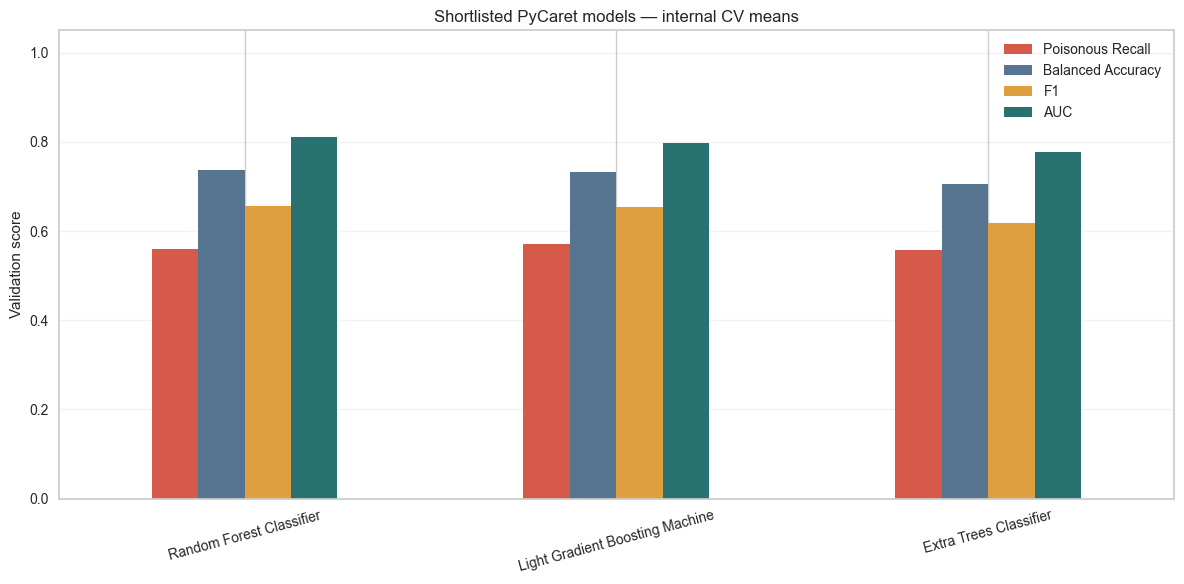

Random Forest Classifier internal validation FN (poisonous predicted edible): 129
Light Gradient Boosting Machine internal validation FN (poisonous predicted edible): 126
Extra Trees Classifier internal validation FN (poisonous predicted edible): 138


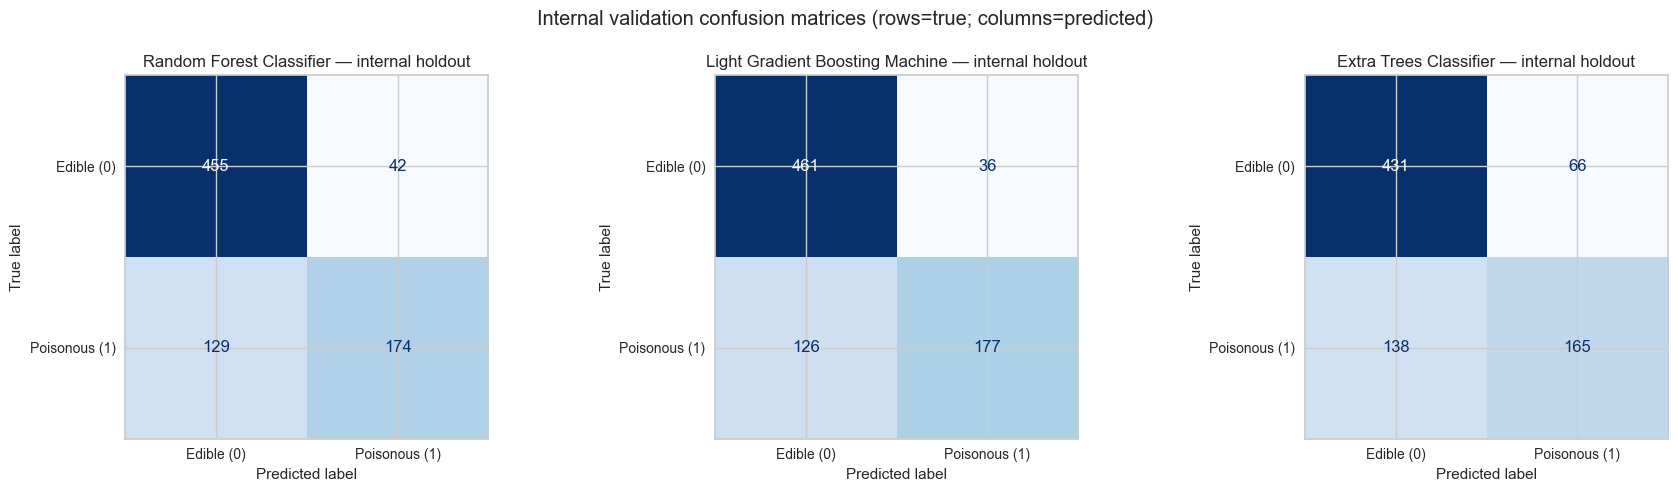

ROC plots use PyCaret internal validation data, not out-of-fold or test predictions.


In [ ]:
# Collect PyCaret's per-fold summary for the shortlisted models, separately from
# predictions made on PyCaret's internal validation holdout.
top_cv_rows = []
top_estimators = {}
holdout_predictions = {}
# Fit each shortlisted estimator with the same configured CV folds and preserve
# both the fitted estimator and its holdout predictions for the follow-up review.
for model_id in selected_ids:
    estimator = experiment.create_model(model_id, fold=cv, verbose=False)
    # PyCaret's results table includes fold rows plus aggregate Mean and Std rows.
    scores = experiment.pull().copy()
    labels = scores['Fold'].astype(str) if 'Fold' in scores else scores.index.astype(str)
    if 'Mean' not in labels.tolist() or 'Std' not in labels.tolist():
        raise RuntimeError(f'Per-fold mean/std rows unavailable for {model_id}.')
    mean_row = scores.loc[labels == 'Mean'].iloc[0]
    std_row = scores.loc[labels == 'Std'].iloc[0]
    row = {'model_id': model_id, 'Model': model_names[model_id]}
    for metric in ['Accuracy', 'AUC', 'Recall', 'Prec.', 'F1', 'Poisonous Recall', 'Balanced Accuracy', 'TT (Sec)']:
        if metric in scores.columns:
            row[f'{metric} mean'] = float(mean_row[metric])
            row[f'{metric} std'] = float(std_row[metric])
    top_cv_rows.append(row)
    top_estimators[model_id] = estimator
    # predict_model returns predictions for PyCaret's internal holdout split;
    # these are not out-of-fold predictions for the full 4,000-row training set.
    holdout_predictions[model_id] = experiment.predict_model(estimator, verbose=False)

top_cv_summary = pd.DataFrame(top_cv_rows).set_index('Model')
display(top_cv_summary.round(4))
model_profiles = {
    'lr': 'Lower complexity; coefficients are relatively interpretable.',
    'dt': 'Single tree; inspectable decision rules.',
    'rf': 'Higher complexity; bagged tree ensemble.',
    'et': 'Higher complexity; randomized tree ensemble.',
    'gbc': 'Higher complexity; sequential boosted trees.',
    'ada': 'Medium/high complexity; sequential weak learners.',
    'knn': 'Instance-based; decisions depend on local neighbors.',
    'rbfsvm': 'Higher complexity; nonlinear kernel decision boundary.',
    'nb': 'Lower complexity; probabilistic assumptions.',
    'lightgbm': 'Higher complexity; boosted tree ensemble.',
    'xgboost': 'Higher complexity; boosted tree ensemble.',
}
top_models['Complexity / interpretability'] = top_models['Model'].map(
    lambda name: model_profiles.get(name_to_id.get(name, ''), 'Inspect estimator before selecting.')
)

# Plot several shortlist metrics together to make trade-offs visible instead of
# sorting only by PyCaret's default accuracy metric.
ax = top_models.set_index('Model')[required_metrics].plot(
    kind='bar', figsize=(12, 6), color=['#d65a4a', '#577590', '#e09f3e', '#287271'])
ax.set_title('Shortlisted PyCaret models — internal CV means')
ax.set_ylabel('Validation score')
ax.set_xlabel('')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
# Save the metric chart before displaying it once; close it to prevent a second
# inline rendering when the cell finishes.
ax.figure.savefig(FIGURE_DIR / 'mushroom_pycaret_comparison.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(ax.figure)

# Build confusion matrices only from the internal validation predictions above.
# With labels ordered [0, 1], cell [1, 0] counts poisonous mushrooms predicted edible.
fig, axes = plt.subplots(1, len(selected_ids), figsize=(6 * len(selected_ids), 5), squeeze=False)
false_negatives = {}
for ax, model_id in zip(axes[0], selected_ids):
    prediction = holdout_predictions[model_id]
    # Fail clearly if the PyCaret version returns a different prediction schema.
    if TARGET not in prediction or 'prediction_label' not in prediction:
        raise RuntimeError(f'PyCaret output missing holdout prediction columns: {prediction.columns.tolist()}')
    # Force class order so TN/FP/FN/TP positions are consistent across all models.
    matrix = confusion_matrix(prediction[TARGET].astype(int), prediction['prediction_label'].astype(int), labels=[0, 1])
    # Record the false-negative count for comparison across shortlisted candidates.
    false_negatives[model_id] = int(matrix[1, 0])
    # Annotate axes with explicit labels so the safety-relevant error is interpretable.
    ConfusionMatrixDisplay(matrix, display_labels=['Edible (0)', 'Poisonous (1)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{model_names[model_id]} — internal holdout')
    print(f'{model_names[model_id]} internal validation FN (poisonous predicted edible): {matrix[1, 0]}')
fig.suptitle('Internal validation confusion matrices (rows=true; columns=predicted)')
fig.tight_layout()
# Persist this internal-holdout plot before rendering it exactly once.
fig.savefig(FIGURE_DIR / 'mushroom_pycaret_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# PyCaret's AUC plot uses the internal validation holdout, not the CV fold
# predictions or held-out final test set; keep this limitation explicit.
for model_id, estimator in top_estimators.items():
    safe_name = ''.join(c.lower() if c.isalnum() else '_' for c in model_names[model_id]).strip('_')
    model_figure_dir = FIGURE_DIR / f'mushroom_pycaret_{safe_name}'
    model_figure_dir.mkdir(parents=True, exist_ok=True)
    experiment.plot_model(estimator, plot='auc', save=str(model_figure_dir), verbose=False)
print('ROC plots use PyCaret internal validation data, not out-of-fold or test predictions.')

## 10. Compare against baseline

Notebook 03 used five-fold CV over all 4,000 rows with the shared sklearn preprocessor. This PyCaret experiment cross-validates only its internal training portion (about 3,200 rows) with PyCaret's own preprocessing. This is exploratory context only; controlled numerical comparisons belong in notebook 05.

In [ ]:
if BASELINE_PATH.is_file():
    baseline = pd.read_csv(BASELINE_PATH)
    display(baseline.loc[baseline['Model'] == 'Logistic Regression'])
    print('Exploratory reference only: CV samples and preprocessing differ from this PyCaret run.')
else:
    print(f'No baseline results found at {BASELINE_PATH}.')

,Model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,poisonous_precision_mean,poisonous_precision_std,poisonous_recall_mean,poisonous_recall_std,poisonous_f1_mean,poisonous_f1_std,roc_auc_mean,roc_auc_std
2,Logistic Regression,0.696,0.0121,0.627851,0.014443,0.699075,0.038815,0.347418,0.032367,0.463269,0.029337,0.688199,0.021634


Exploratory reference only: CV samples and preprocessing differ from this PyCaret run.


## 11. Interpretation and candidate decision

Poisonous recall is important because false negatives miss poisonous cases. Recall alone is insufficient: predicting all mushrooms poisonous would achieve perfect recall but be poor at identifying edible cases. Review precision, balanced accuracy, F1, ROC-AUC, false negatives, runtime, and complexity together. Use this shortlist for controlled comparisons in notebook 05; do not declare a final winner here.

In [ ]:
print('Shortlisted candidates (average rank across recall, balanced accuracy, F1, ROC-AUC):')
display(top_models[['Model', *required_metrics, 'Complexity / interpretability']])
print('PyCaret internally validates on the reserved holdout; CV means/stds describe only its training partition.')

Shortlisted candidates (average rank across recall, balanced accuracy, F1, ROC-AUC):


,Model,Poisonous Recall,Balanced Accuracy,F1,AUC,Complexity / interpretability
2,Random Forest Classifier,0.5607,0.7361,0.6566,0.8112,Higher complexity; bagged tree ensemble.
1,Light Gradient Boosting Machine,0.5715,0.7314,0.6528,0.7968,Higher complexity; boosted tree ensemble.
3,Extra Trees Classifier,0.5582,0.7045,0.6178,0.7774,Higher complexity; randomized tree ensemble.


PyCaret internally validates on the reserved holdout; CV means/stds describe only its training partition.


## 12. Save results and conclusions

Save PyCaret outputs separately from baseline files. The full comparison table contains CV means; shortlist score grids provide fold means and standard deviations. Do not save or deploy a final production model.

In [ ]:
comparison.to_csv(DATA_DIR / 'mushroom_pycaret_comparison.csv', index=False)
top_models.merge(top_cv_summary.reset_index(), on='Model', how='left').to_csv(
    DATA_DIR / 'mushroom_pycaret_top_models.csv', index=False)
summary = {
    'dataset_rows': int(len(train_data)),
    'target_mapping': TARGET_MAPPING,
    'positive_class': 1,
    'pycaret_version': PYCARET_VERSION,
    'random_seed': RANDOM_STATE,
    'cross_validation': {'strategy': 'StratifiedKFold', 'folds': N_SPLITS, 'shuffle': True, 'random_state': RANDOM_STATE},
    'models_evaluated': include_models,
    'shortlisted_model_ids': selected_ids,
    'sorting_metric': 'Poisonous Recall',
    'internal_train_fraction': INTERNAL_TRAIN_SIZE,
    'setup': {'numeric_imputation': 'median', 'categorical_imputation': '__missing__', 'normalize': True, 'feature_selection': False, 'remove_outliers': False, 'fix_imbalance': False},
    'limitations': [
        'PyCaret CV uses about 3,200 of the 4,000 supplied training rows; notebook 03 uses all 4,000.',
        'PyCaret preprocessing differs from the shared sklearn baseline preprocessor.',
        'Confusion matrices and ROC plots use PyCaret internal validation data, not CV OOF predictions or final test data.',
        'No tuning, threshold optimization, automatic balancing, or production model saving was performed.'
    ],
}
(DATA_DIR / 'mushroom_pycaret_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved PyCaret comparison, shortlist, summary, and figures under', DATA_DIR)
print('Next: compare candidates in notebook 05 using the same 4,000 raw training rows, folds, and shared pipeline.')

Saved PyCaret comparison, shortlist, summary, and figures under /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5/mushroom/data
Next: compare candidates in notebook 05 using the same 4,000 raw training rows, folds, and shared pipeline.
